

**The model: FLUX.2 [klein] 4B** (Black Forest Labs, Apache 2.0, open weights). Unlike the earlier notebooks, it is trained to follow **edit instructions** directly, so you type the sentence as you would in a chat. It makes a result in 4 steps. Compound edits and follow-ups work the way they do in the screenshots: each follow-up edits the previous result.

**Optional pixel-exact protection.** For "keep the face intact" or "the dog should be untouched", the notebook can paste the **original** face or subject back over the result, so those pixels are identical to your photo. (Segmentation by `rembg` for subjects and `segformer_b2_clothes` for faces.)

## Read this first: hardware

FLUX.2 klein 4B needs about 13 GB of GPU memory according to its model card, and it is **much bigger than the models in my earlier notebooks**. The notebook picks a mode for your GPU:

| GPU | mode | notes |
|---|---|---|
| 22 GB or more (Colab **L4** or A100, RTX 3090 or better) | full precision | fastest and most reliable. Recommended |
| 15-16 GB (free Colab **T4**, Kaggle) | 4-bit compressed | **experimental.** It should fit, but I could not test it on a T4. T4 has no native bfloat16 so the model runs in float16, which can give blank images. If that happens, use an L4 |

**Before you start:** Runtime → Change runtime type → choose the GPU. If Colab crashed earlier with "ran out of RAM", choose **Runtime → Restart session** first. Run each cell **once**, from top to bottom. The first run downloads about 16 GB (one time per session). If Colab asks you to restart after the install cell, do it and continue from section 2.

## 1. Install

In [1]:
!pip install -q -U git+https://github.com/huggingface/diffusers
!pip install -q -U transformers accelerate safetensors bitsandbytes rembg onnxruntime opencv-python-headless psutil

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Load the model

The model is loaded straight onto the GPU, and the notebook prints how much RAM and GPU memory it uses. Run this cell once.

In [2]:
import gc, os, random, re, zipfile
from datetime import datetime

import cv2
import numpy as np
import torch
from PIL import Image, ImageOps
from PIL.PngImagePlugin import PngInfo
from IPython.display import display
from diffusers import Flux2KleinPipeline

REPO = "black-forest-labs/FLUX.2-klein-4B"      # Apache 2.0. One model for generating AND editing images from instructions

def ram(label):
    """Prints how much system RAM is in use, so you can see where memory goes."""
    try:
        import psutil
        m = psutil.virtual_memory()
        used = (m.total - m.available) / 1e9
        print(f"[RAM] {label}: {used:.1f} GB used of {m.total / 1e9:.1f} GB")
        return used
    except Exception:
        return 0.0

if not torch.cuda.is_available():
    raise RuntimeError("No GPU found, so loading the model would run out of memory. In Colab: Runtime > Change runtime "
                       "type > choose a GPU, then Runtime > Restart session and run the cells again.")

try:                                             # optional Hugging Face token (only needed if the download asks you to log in)
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

vram = torch.cuda.get_device_properties(0).total_memory / 1e9
native_bf16 = torch.cuda.get_device_capability(0)[0] >= 8
dtype = torch.bfloat16 if native_bf16 else torch.float16
FULL_PRECISION = vram >= 22                      # L4 / A100 / RTX 3090 or better
print(f"GPU: {torch.cuda.get_device_name(0)} | {vram:.0f} GB | "
      f"{'native bfloat16' if native_bf16 else 'no native bfloat16, using float16'} | "
      f"mode: {'full precision' if FULL_PRECISION else '4-bit compressed (fits a 15-16 GB GPU)'}")
if ram("before loading") > 4.0:
    print("WARNING: this session already uses a lot of RAM (models from an earlier run?). "
          "Choose Runtime > Restart session, then run the cells again, each only once.")

kwargs = dict(torch_dtype=dtype)
if not FULL_PRECISION:
    from diffusers.quantizers import PipelineQuantizationConfig
    kwargs["quantization_config"] = PipelineQuantizationConfig(
        quant_backend="bitsandbytes_4bit",
        quant_kwargs={"load_in_4bit": True, "bnb_4bit_quant_type": "nf4", "bnb_4bit_compute_dtype": dtype},
        components_to_quantize=["transformer", "text_encoder"])     # the two big parts, compressed while loading

pipe = None
try:
    pipe = Flux2KleinPipeline.from_pretrained(REPO, device_map="cuda", **kwargs)      # straight onto the GPU
except Exception as e:
    msg = str(e)
    if any(w in msg.lower() for w in ("401", "gated", "log in", "access to model")):
        raise RuntimeError("Hugging Face asks you to log in. Create a free token at huggingface.co/settings/tokens, add it in "
                           "Colab Secrets (key icon) as HF_TOKEN, switch on Notebook access, restart the session and try again.")
    print("Direct-to-GPU loading did not work, trying again with CPU offload:", msg[:120])
    gc.collect()
    pipe = Flux2KleinPipeline.from_pretrained(REPO, **kwargs)
    pipe.enable_model_cpu_offload()
gc.collect()
ram("after loading")
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
print("Ready:", REPO)

GPU: Tesla T4 | 16 GB | no native bfloat16, using float16 | mode: 4-bit compressed (fits a 15-16 GB GPU)
[RAM] before loading: 3.8 GB used of 13.6 GB


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/446 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[RAM] after loading: 2.2 GB used of 13.6 GB
GPU memory used: 5.2 GB
Ready: black-forest-labs/FLUX.2-klein-4B


## 3. The editing functions

`keep` controls the optional pixel-exact protection:

| keep | what is pasted back from your photo | use it for |
|---|---|---|
| `none` | nothing | edits that touch the person, e.g. a bindi, new clothes with hair changes |
| `face` | the face (and sunglasses) | changing clothes or background while the face must stay identical |
| `subject` | the whole main subject (person, pet, object) | changing the background only ("the dog should be untouched") |

The notebook suggests a value from your sentence. You can change it.

In [3]:
os.makedirs("outputs", exist_ok=True)

STEPS = 4                      # FLUX.2 klein is a 4-step model
GUIDANCE = 1.0                 # distilled model: keep at 1.0
KEEP_HINT = " Keep everything else exactly the same, including faces, identity, pose and lighting."
FOREHEAD_WORDS = ["bindi", "tilak", "tika", "forehead", "makeup", "lipstick", "glasses", "sunglasses", "earring", "mask"]

def prepare_input(image):
    """Fix rotation, force RGB, and size the picture for the model (long side 768-1024, multiples of 16, same aspect ratio)."""
    image = ImageOps.exif_transpose(image).convert("RGB")
    w, h = image.size
    target = min(1024, max(768, max(w, h)))
    s = target / max(w, h)
    return image.resize((max(256, round(w * s / 16) * 16), max(256, round(h * s / 16) * 16)), Image.LANCZOS)

def looks_blank(img):
    return float(np.asarray(img, dtype=np.float32).std()) < 3.0

# ---------- keeping parts of the original exactly as they were (optional) ----------
_rembg_session = None
_seg = None

def subject_matte(image):
    """Soft 0-1 mask of the main subject (person, pet, object) using rembg."""
    global _rembg_session
    from rembg import remove, new_session
    if _rembg_session is None:
        _rembg_session = new_session("isnet-general-use")
    return np.asarray(remove(image, session=_rembg_session, only_mask=True).convert("L"), dtype=np.float32) / 255.0

def face_matte(image):
    """0-1 mask of the face (and sunglasses) using a small human-parsing model."""
    global _seg
    from transformers import SegformerImageProcessor, AutoModelForSemanticSegmentation
    if _seg is None:
        _seg = (SegformerImageProcessor.from_pretrained("mattmdjaga/segformer_b2_clothes"),
                AutoModelForSemanticSegmentation.from_pretrained("mattmdjaga/segformer_b2_clothes").eval())
    proc, model = _seg
    inputs = proc(images=image, return_tensors="pt")
    with torch.no_grad():
        logits = model(**inputs).logits
    logits = torch.nn.functional.interpolate(logits, size=(image.height, image.width), mode="bilinear", align_corners=False)
    labels = logits.argmax(dim=1)[0].to("cpu").numpy()
    return np.isin(labels, [3, 11]).astype(np.float32)

def paste_back(source, edited, mode):
    """Puts the ORIGINAL face or subject back over the edited picture, so those pixels are identical to your photo."""
    edited = edited.resize(source.size, Image.LANCZOS)
    m = subject_matte(source) if mode == "subject" else face_matte(source)
    core = (m > 0.5).astype(np.uint8)
    k = max(2, round(max(source.size) / 400))                       # shrink a little so no old-background halo is pasted
    core = cv2.erode(core, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * k + 1, 2 * k + 1)))
    alpha = cv2.GaussianBlur(core.astype(np.float32), (0, 0), max(1.0, k / 2))[..., None]
    out = np.asarray(source, dtype=np.float32) * alpha + np.asarray(edited, dtype=np.float32) * (1 - alpha)
    return Image.fromarray(np.clip(out + 0.5, 0, 255).astype(np.uint8)), 100.0 * float((alpha > 0.99).mean())

def default_keep(instruction):
    low = instruction.lower()
    if re.search(r"\b(background|backdrop)\b", low):
        return "subject"
    if re.search(r"\b(face|facial|features|identity)\b", low) and not any(w in low for w in FOREHEAD_WORDS):
        return "face"
    return "none"

# ---------- one edit ----------
def _save(image, instruction, seed):
    meta = PngInfo()                                                # remove these 3 lines if you do not want the
    meta.add_text("prompt", instruction)                            # instruction and seed stored inside the saved file
    meta.add_text("seed", str(seed))
    path = f"outputs/edited_{datetime.now():%Y%m%d_%H%M%S}_{seed}.png"
    image.save(path, pnginfo=meta)
    return path

def edit(image, instruction, keep="none", n_images=1, seed=-1, steps=STEPS, keep_hint=True):
    """Edits the picture from a sentence. keep = 'none', 'face' or 'subject'. Returns a list of (image, saved path)."""
    src = prepare_input(image)
    prompt = instruction.strip() + (KEEP_HINT if keep_hint else "")
    seed = int(seed)
    if seed < 0:
        seed = random.randint(0, 2**31 - 1)
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    results = []
    for i in range(int(n_images)):
        s = seed + i
        try:
            out = pipe(image=src, prompt=prompt, num_inference_steps=int(steps), guidance_scale=GUIDANCE,
                       generator=torch.Generator(device="cpu").manual_seed(s)).images[0]
        except oom:
            gc.collect(); torch.cuda.empty_cache()
            raise RuntimeError("Out of GPU memory. Restart the session (Runtime > Restart session) and run again.")
        if looks_blank(out):
            print(f"Result {i + 1} came back blank. This is a known float16 problem on older GPUs (like the T4). "
                  "Try another seed, or use a GPU with native bfloat16 (Colab L4 or A100).")
            continue
        if keep in ("face", "subject"):
            try:
                out, pct = paste_back(src, out, keep)
                print(f"Result {i + 1}: original {keep} put back exactly as in your photo ({pct:.0f}% of the picture is pixel-identical)")
            except Exception as e:
                print(f"Result {i + 1}: could not keep the original {keep} ({str(e)[:80]}); showing the edit as it is.")
        results.append((out, _save(out, instruction, s)))
        gc.collect()
        torch.cuda.empty_cache()
    return results

def download(results):
    """One picture downloads as a PNG. Several pictures download as one zip (avoids browser pop-up blocking)."""
    paths = [p for _, p in results]
    if len(paths) > 1:
        zip_path = f"outputs/images_{datetime.now():%Y%m%d_%H%M%S}.zip"
        with zipfile.ZipFile(zip_path, "w") as z:
            for p in paths:
                z.write(p, os.path.basename(p))
        target = zip_path
    else:
        target = paths[0]
    try:                                                            # in Colab this starts a browser download
        from google.colab import files
        files.download(target)
    except ImportError:
        print("Not in Colab: the files are in the 'outputs' folder next to this notebook.")
    print("Download:", target)

## 4. Upload, write the instruction, download

Run the cell, upload your photo, and type the change like a chat message. After each result you can type another change, and it edits the picture you just made. Press **Enter** with nothing typed to finish. Every result downloads automatically (several results come as one zip).

Saving 134111172756186053.jpg to 134111172756186053.jpg


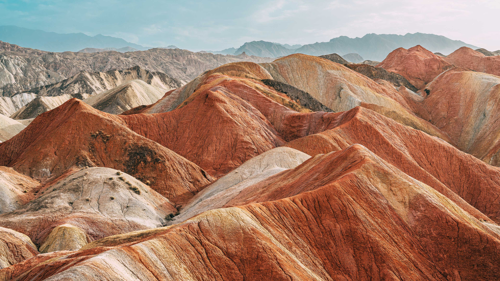

What should change? Write it like a chat message, e.g. 'the girl should wear a white shirt keeping the facial features intact': change the sky to a night sky and adjust the colours of the image as it would look when clicked at night with a camera
Number of results per change [1-3, Enter = 1]: 1

--- Change 1: change the sky to a night sky and adjust the colours of the image as it would look when clicked at night with a camera
Keep exactly as in your photo: the face, the whole subject, or nothing (none, face, subject) [Enter = none]: none
Working... about a minute per picture.


  0%|          | 0/4 [00:00<?, ?it/s]

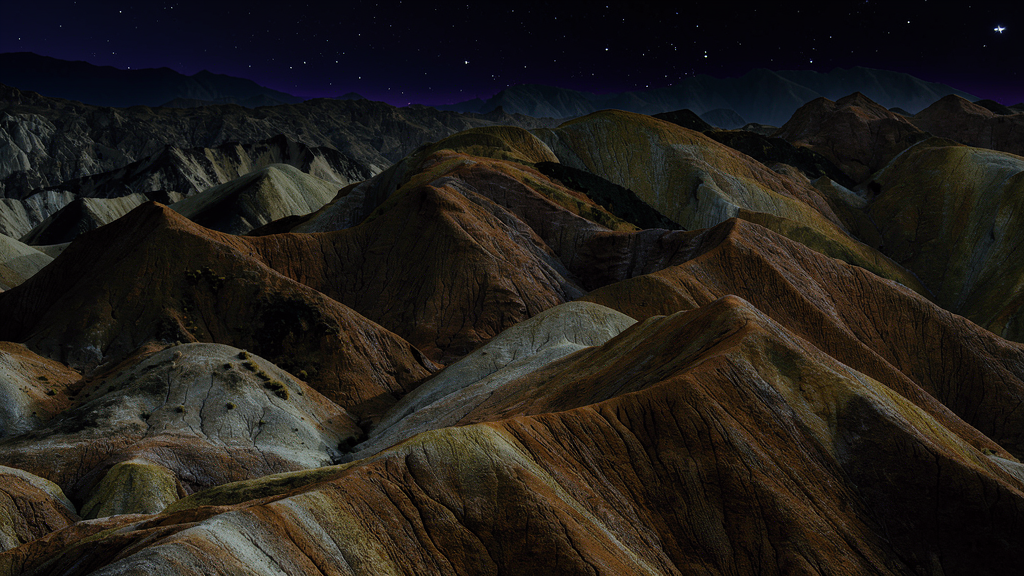

Result 1 saved: outputs/edited_20261110_124429_260650678.png | size: (1024, 576)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download: outputs/edited_20261110_124429_260650678.png

Another change to this picture? Type it, or press Enter to finish: 
Done. All pictures are in the outputs/ folder.


In [9]:
from google.colab import files
uploaded = files.upload()
current = ImageOps.exif_transpose(Image.open(next(iter(uploaded)))).convert("RGB")
shown = current.copy(); shown.thumbnail((500, 500)); display(shown)

def ask_number(question, default, low, high, cast=float):
    while True:
        text = input(f"{question} [{low}-{high}, Enter = {default}]: ").strip()
        if not text:
            return default
        try:
            value = cast(text)
            if low <= value <= high:
                return value
        except ValueError:
            pass
        print(f"  Please type a number between {low} and {high}.")

def ask_choice(question, options, default):
    while True:
        text = input(f"{question} ({', '.join(options)}) [Enter = {default}]: ").strip().lower()
        if not text:
            return default
        if text in options:
            return text
        print("  Please type one of:", ", ".join(options))

instruction = input("What should change? Write it like a chat message, e.g. 'the girl should wear a white shirt keeping the facial features intact': ").strip()
while not instruction:
    instruction = input("The instruction can't be empty. What should change? ").strip()
n_images = ask_number("Number of results per change", 1, 1, 3, int)

turn = 1
while True:
    print(f"\n--- Change {turn}: {instruction}")
    keep = ask_choice("Keep exactly as in your photo: the face, the whole subject, or nothing", ["none", "face", "subject"],
                      default_keep(instruction))
    print("Working... about a minute per picture.")
    results = edit(current, instruction, keep=keep, n_images=n_images)
    if not results:
        break
    for i, (image, path) in enumerate(results, 1):
        display(image)
        print(f"Result {i} saved: {path} | size: {image.size}")
    download(results)
    pick = 1 if len(results) == 1 else ask_number("Which result do you want to continue from", 1, 1, len(results), int)
    current = results[pick - 1][0]
    instruction = input("\nAnother change to this picture? Type it, or press Enter to finish: ").strip()
    if not instruction:
        break
    turn += 1
print("Done. All pictures are in the outputs/ folder.")

## Tips and limits

- **Write it like a chat message**, with the details: colours, fabric, style. Several changes in one sentence work, but if one is missed, do it as a follow-up.
- **Say what to keep**: *"keep her face and hair exactly the same"*. The notebook adds a short "keep everything else the same" line for you.
- **Small details** (a bindi, jewellery, text) can come out larger, smaller or in the wrong place. Ask for it again with a follow-up like *"make the bindi smaller"*, or try another seed by running the change again.
- **Pixel-exact protection** pastes the original pixels back, so a face can look slightly different in lighting from the edited surroundings. If a result looks pasted, use `none`.
- **Blank image on a T4:** known float16 problem. Use an L4 or A100 GPU.
- The result is about 1 megapixel (long side up to 1024).
- Only edit photos of people you have permission to edit.